In [7]:
import pandas as pd
import numpy as np

# Data Preparation

### Data Splitting

In [8]:
df = pd.read_csv('/Users/yudhapratama/Documents/Science/Publikasi/clean-water-access/data/clean_water.csv')
# df = df[df['water']>0]
df.describe()

,year,water,expend,morbid,pop,pad,area,logpop,logpad,logarea,logexpend
count,10180.000000,10180.000000,1.018000e+04,10180.000000,1.018000e+04,1.018000e+04,10180.000000,10180.000000,10180.000000,10180.000000,10180.000000
mean,2009.288016,53.503343,8.291191e+11,28.374057,5.367172e+05,1.012712e+11,4557.257763,12.717604,24.195068,7.414120,27.066711
std,6.902330,22.295985,7.938387e+11,8.630118,5.944834e+05,2.585932e+11,7868.113495,0.987988,1.536994,1.634336,0.886080
min,1996.000000,0.000000,1.650104e+08,2.860000,1.260700e+04,2.490000e+07,6.000000,9.442007,17.030378,1.791759,18.921519
25%,2004.000000,36.867500,2.395162e+11,22.560000,1.671970e+05,1.160103e+10,827.000000,12.026928,23.174359,6.717805,26.201887
50%,2010.000000,53.540000,6.077917e+11,27.860000,3.113135e+05,3.241010e+10,1902.370000,12.648556,24.201736,7.550856,27.133098
75%,2015.000000,70.437500,1.097279e+12,33.730000,7.155552e+05,9.387414e+10,4950.400000,13.480814,25.265221,8.507224,27.723855
max,2020.000000,100.000000,9.162656e+12,77.120000,6.398000e+06,5.381920e+12,119749.000000,15.671496,29.314066,11.693153,29.846157


In [9]:
X = df[['logpop','logarea','logpad','year','morbid','daerah','tingkat','status']]
y = df['water']

In [10]:
print(X.head())
print(y.head())
print(df['id'].head())

      logpop   logarea     logpad  year  morbid  daerah tingkat       status
0  12.662231  6.037871  25.115433  1996   28.46  Badung     Kab  Kota Sedang
1  12.682617  6.037871  25.285416  1997   28.05  Badung     Kab  Kota Sedang
2  12.702901  6.037871  26.105214  1998   23.42  Badung     Kab  Kota Sedang
3  12.722781  6.037871  26.260208  1999   32.92  Badung     Kab  Kota Sedang
4  12.736563  6.037871  26.112338  2000   26.37  Badung     Kab  Kota Sedang
0    42.52
1    38.60
2    40.72
3    36.70
4    48.57
Name: water, dtype: float64
0    ID.BA.BD
1    ID.BA.BD
2    ID.BA.BD
3    ID.BA.BD
4    ID.BA.BD
Name: id, dtype: str


In [11]:
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV, TimeSeriesSplit

X_train, X_test, y_train, y_test= train_test_split(
    X,
    y,  
    test_size=0.2,
    shuffle=True)

# Basic Model

### Model Prep

In [12]:
#Transform
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
import category_encoders as ce
from sklearn.preprocessing import RobustScaler

from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost.sklearn import XGBRegressor

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV, GridSearchCV, KFold

from sklearn.pipeline import Pipeline

In [13]:
transformer = ColumnTransformer(
    transformers=[
        ('kategorikal', OneHotEncoder(drop='first'), ['year','status','tingkat']),
        ('Binary',ce.BinaryEncoder(),['daerah'])
    ],remainder='passthrough'
)

scaler = RobustScaler()

In [14]:
lr = LinearRegression()
knn = KNeighborsRegressor()
dt = DecisionTreeRegressor(random_state=1)
rf = RandomForestRegressor(random_state=1)
xgb = XGBRegressor(random_state=1)

models = [lr,knn,dt,rf,xgb]
          
score_rmse = []
nilai_mean_rmse = []
nilai_std_rmse = []

score_mae = []
nilai_mean_mae = []
nilai_std_mae = []

score_mape = []
nilai_mean_mape = []
nilai_std_mape = []

In [15]:
for i in models:
    
    crossval = KFold(n_splits=5, shuffle=True, random_state=1)

    estimator = Pipeline([
        ('preprocessing', transformer),
        ('scaler', scaler),
        ('model', i)
    ])

    # RMSE
    model_cv_rmse = cross_val_score(
        estimator, 
        X_train, 
        y_train, 
        cv=crossval, 
        scoring='neg_root_mean_squared_error', 
        error_score='raise'
        )

    print(model_cv_rmse, i)

    score_rmse.append(model_cv_rmse)
    nilai_mean_rmse.append(model_cv_rmse.mean())
    nilai_std_rmse.append(model_cv_rmse.std())

    # MAE
    model_cv_mae = cross_val_score(
        estimator, 
        X_train, 
        y_train, 
        cv=crossval, 
        scoring='neg_mean_absolute_error', 
        error_score='raise'
        )

    print(model_cv_mae, i)

    score_mae.append(model_cv_mae)
    nilai_mean_mae.append(model_cv_mae.mean())
    nilai_std_mae.append(model_cv_mae.std())

    # MAPE
    model_cv_mape = cross_val_score(
        estimator, 
        X_train, 
        y_train, 
        cv=crossval, 
        scoring='neg_mean_absolute_percentage_error', 
        error_score='raise'
        )

    print(model_cv_mape, i)

    score_mape.append(model_cv_mape)
    nilai_mean_mape.append(model_cv_mape.mean())
    nilai_std_mape.append(model_cv_mape.std())

[-15.38376508 -14.94992665 -14.56463729 -15.23300889 -14.5350634 ] LinearRegression()
[-12.03080656 -11.68292163 -11.41290914 -11.81812634 -11.41646738] LinearRegression()
[-8.24382386e-01 -1.33439827e+14 -1.05974534e+14 -1.49439862e+14
 -5.47653508e-01] LinearRegression()
[-10.8193517  -10.463439   -10.43656016 -10.6507004  -10.70597025] KNeighborsRegressor()
[-8.20692572 -7.81579251 -7.93401228 -8.00611664 -8.21836855] KNeighborsRegressor()
[-4.63537341e-01 -9.06359792e+13 -3.94569514e+13 -1.17121237e+14
 -3.75160634e-01] KNeighborsRegressor()
[-14.86191433 -14.46618055 -15.76642754 -15.2938858  -15.62251987] DecisionTreeRegressor(random_state=1)
[-10.62520565 -10.35502762 -11.13219767 -11.01993247 -11.21830467] DecisionTreeRegressor(random_state=1)
[-4.51147704e-01 -7.73546455e+13 -1.32979216e+13 -1.74365886e+14
 -3.54738165e-01] DecisionTreeRegressor(random_state=1)
[-11.0446127  -10.54615869 -10.78442621 -11.15133097 -10.62512361] RandomForestRegressor(random_state=1)
[-8.49451627

In [16]:
# Evaluasi hasil dari 5 kandidat algoritma yang digunakan
pd.DataFrame({
    'Model': ['Linear Regression', 'KNN Regressor', 'DecisionTree Regressor', 'RandomForest Regressor', 'XGBoost Regressor'],
    'Mean_RMSE': nilai_mean_rmse,
    'Std_RMSE': nilai_std_rmse,
    'Mean_MAE': nilai_mean_mae,
    'Std_MAE': nilai_std_mae,
    'Mean_MAPE': nilai_mean_mape,
    'Std_MAPE': nilai_std_mape
})

,Model,Mean_RMSE,Std_RMSE,Mean_MAE,Std_MAE,Mean_MAPE,Std_MAPE
0,Linear Regression,-14.933280,0.342790,-11.672246,0.237756,-7.777084e+13,6.500391e+13
1,KNN Regressor,-10.615204,0.145685,-8.036243,0.156371,-4.944283e+13,4.746819e+13
2,DecisionTree Regressor,-15.202186,0.481860,-10.870134,0.327922,-5.300369e+13,6.710750e+13
3,RandomForest Regressor,-10.830330,0.234064,-8.249476,0.164036,-5.612724e+13,5.972966e+13
4,XGBoost Regressor,-10.222791,0.220143,-7.829335,0.165914,-5.279725e+13,6.255648e+13


In [17]:
# Benchmark 2 model terbaik
models = {
    'XGB': XGBRegressor(random_state=1),
    'RandomForest': RandomForestRegressor(random_state=1)
}

score_rmse = []
score_mae = []
score_mape = []

# Prediksi pada test set
for i in models:

    model = Pipeline([
        ('preprocessing', transformer),
        ('scaler', scaler),
        ('model', models[i])
        ])

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    score_rmse.append(np.sqrt(mean_squared_error(y_test, y_pred)))
    score_mae.append(mean_absolute_error(y_test, y_pred))
    score_mape.append(mean_absolute_percentage_error(y_test, y_pred))

score_before_tuning = pd.DataFrame({'RMSE': score_rmse, 'MAE': score_mae, 'MAPE': score_mape}, index=models.keys())
score_before_tuning

,RMSE,MAE,MAPE
XGB,10.231031,7.740215,9.435450e+12
RandomForest,10.587867,7.978450,2.692914e+13


### Hyperparameter Tuning

In [18]:
# xgb
max_depth = list(np.arange(3, 11)) # Kedalaman pohon
learning_rate = list(np.arange(1, 4)/100) # Learning rate
n_estimators = list(np.arange(100, 1001)) # Jumlah pohon
subsample = list(np.arange(6, 11)/10) # Jumlah baris tiap pohon (% dari total baris train set)
gamma = list(np.arange(1, 6)/10) # Semakin besar nilainya, semakin konservatif/simpel modelnya
colsample_bytree = list(np.arange(5, 11)/10) # Jumlah feature yang digunakan untuk tiap pohon (% dari total kolom train set)
reg_alpha = list(np.arange(5, 50)/100) # Semakin besar nilainya, semakin konservatif/simpel modelnya
eta = [0.01, 0.05, 0.1, 0.2, 0.3]

min_child_weight = list(np.arange(1, 11))

# Hyperparam space XGboost
hyperparam_space_xgb = {
    'model__max_depth': max_depth, 
    'model__learning_rate': learning_rate,
    'model__n_estimators': n_estimators,
    'model__subsample': subsample,
    'model__gamma': gamma,
    'model__colsample_bytree': colsample_bytree,
    'model__reg_alpha': reg_alpha,
    'model__eta': eta,
}

In [19]:
# Benchmark model dengan hyperparameter tuning
xgb = XGBRegressor(random_state=2023)

# Membuat algorithm chains
estimator_xgb = Pipeline([
        ('preprocessing', transformer),
        ('scaler',scaler),
        ('model', xgb)
        ])

crossval = crossval

# Hyperparameter tuning
random_xgb = RandomizedSearchCV(
    estimator_xgb, 
    param_distributions = hyperparam_space_xgb,
    n_iter = 50,
    cv = crossval, 
    scoring = ['neg_root_mean_squared_error', 'neg_mean_absolute_percentage_error'], 
    n_jobs = -1,
    refit = 'neg_root_mean_squared_error', # Hanya bisa memilih salah stau metric untuk optimisasi
    random_state = 2022  
)

In [20]:
random_xgb.fit(X_train, y_train)

/Users/yudhapratama/Documents/Science/Publikasi/clean-water-access/.venv/lib/python3.14/site-packages/sklearn/externals/_numpydoc/docscrape.py:420: UserWarning: Unknown section Example
  self[section] = content


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__colsample_bytree': [np.float64(0.5), np.float64(0.6), ...], 'model__eta': [0.01, 0.05, ...], 'model__gamma': [np.float64(0.1), np.float64(0.2), ...], 'model__learning_rate': [np.float64(0.01), np.float64(0.02), ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",50
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.","['neg_root_mean_squared_error', 'neg_mean_absolute_percentage_error']"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'neg_root_mean_squared_error'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` is

In [21]:
# Cek skor dan params terbaik
print('XGBoost')
print('Best_score:', random_xgb.best_score_)
print('Best_params:', random_xgb.best_params_)

XGBoost
Best_score: -9.444007439487734
Best_params: {'model__subsample': np.float64(0.6), 'model__reg_alpha': np.float64(0.4), 'model__n_estimators': np.int64(915), 'model__max_depth': np.int64(9), 'model__learning_rate': np.float64(0.03), 'model__gamma': np.float64(0.1), 'model__eta': 0.3, 'model__colsample_bytree': np.float64(0.5)}


In [25]:
# Model XGBoost
model = {'XGB': XGBRegressor(random_state=2023)}

# Define model terhadap estimator terbaik
tuned_model = random_xgb.best_estimator_

# Fitting model
tuned_model.fit(X_train, y_train)

# Predict test set
y_pred_tuned = tuned_model.predict(X_test)

# Simpan nilai metrics RMSE, MAE setelah tuning
rmse_xgb_tuned = np.sqrt(mean_squared_error(y_test, y_pred_tuned))
mae_xgb_tuned = mean_absolute_error(y_test, y_pred_tuned)

score_after_tuning = pd.DataFrame({'RMSE': rmse_xgb_tuned, 'MAE': mae_xgb_tuned}, index=model.keys())
score_after_tuning

,RMSE,MAE
XGB,9.426814,7.184677


In [26]:
pd.DataFrame(score_before_tuning.iloc[0])

,XGB
RMSE,1.023103e+01
MAE,7.740215e+00
MAPE,9.435450e+12


In [27]:
score_after_tuning.T

,XGB
RMSE,9.426814
MAE,7.184677


### Hyperparameter Tuning - Optuna

In [42]:
import optuna
from sklearn.model_selection import cross_val_score
from xgboost.sklearn import XGBRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error
import numpy as np

In [43]:
def objective(trial):
    params = {
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        'learning_rate': trial.suggest_float('learning_rate', 0.005, 0.3, log=True),
        'n_estimators': trial.suggest_int('n_estimators', 100, 1500),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'gamma': trial.suggest_float('gamma', 0, 5.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 15),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-4, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-4, 10.0, log=True),
        
        'enable_categorical': True,
        'tree_method': 'hist',
        'random_state': 2023
    }
    
    xgb = XGBRegressor(**params)
    
    estimator = Pipeline([
        ('preprocessing', transformer),
        ('model', xgb)
    ])
    
    score = cross_val_score(
        estimator, X_train, y_train, 
        scoring='neg_root_mean_squared_error', 
        cv=crossval, 
        n_jobs=-1
    )
    
    return -score.mean()

In [44]:
print("Memulai proses optimisasi Optuna...")
study = optuna.create_study(direction='minimize')

study.optimize(objective, n_trials=50) 

print(f"\nBest RMSE: {study.best_value:.4f}")
print("Parameter Terbaik yang Ditemukan:")
for key, value in study.best_params.items():
    print(f"  {key}: {value}")


best_params = study.best_params
best_params['enable_categorical'] = True
best_params['tree_method'] = 'hist'
best_params['random_state'] = 2023

best_xgb = XGBRegressor(**best_params)
estimator_final = Pipeline([
    ('preprocessing', transformer),
    ('model', best_xgb)
])

[I 2026-09-05 06:51:50,352] A new study created in memory with name: no-name-197969ba-ea1b-4778-9952-ae608c093901


Memulai proses optimisasi Optuna...


[I 2026-09-05 06:51:52,524] Trial 0 finished with value: 11.20148198819596 and parameters: {'max_depth': 3, 'learning_rate': 0.0865714079896636, 'n_estimators': 1212, 'subsample': 0.5851310856535452, 'colsample_bytree': 0.9123278939221511, 'gamma': 2.5771285901483525, 'min_child_weight': 15, 'reg_alpha': 5.254935478468326, 'reg_lambda': 0.35856236331673813}. Best is trial 0 with value: 11.20148198819596.
[I 2026-09-05 06:51:53,783] Trial 1 finished with value: 10.746212824864944 and parameters: {'max_depth': 5, 'learning_rate': 0.16897936786139087, 'n_estimators': 198, 'subsample': 0.9160989032899263, 'colsample_bytree': 0.7058965667162008, 'gamma': 3.641921278261813, 'min_child_weight': 13, 'reg_alpha': 0.0007359124238980769, 'reg_lambda': 3.0786516659380205}. Best is trial 1 with value: 10.746212824864944.
[I 2026-09-05 06:51:55,062] Trial 2 finished with value: 9.695044599528588 and parameters: {'max_depth': 8, 'learning_rate': 0.14046440693252535, 'n_estimators': 187, 'subsample': 


Best RMSE: 8.9688
Parameter Terbaik yang Ditemukan:
  max_depth: 11
  learning_rate: 0.02930087817027042
  n_estimators: 1393
  subsample: 0.688358584350867
  colsample_bytree: 0.7726078706105914
  gamma: 0.9667010571310165
  min_child_weight: 14
  reg_alpha: 0.08755429940942772
  reg_lambda: 2.0390337915370043


In [45]:
estimator_final.fit(X_train, y_train)

y_pred_test = estimator_final.predict(X_test)
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
print(f"\n Final Test RMSE: {test_rmse:.4f}")


 Final Test RMSE: 8.7920


## Export Model

In [28]:
import pickle

estimator = Pipeline([
        ('preprocessing',transformer),
        ('scaler', scaler),
        ('model',XGBRegressor())
    ])
estimator.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['logpop','logarea','logpad',...,'daerah','tingkat','status']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('kategorikal', ...), ('Binary', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of c

In [29]:
pickle.dump(estimator, open('Model_AirBersih_.pkl', 'wb'))

In [30]:
import pickle
from time import time

# set filename
milliseconds = int(time() * 1000)
filename = f'model_{milliseconds}.sav'

#save the model to disk
pickle.dump(tuned_model, open(filename, 'wb'))


### Mencoba Modelnya

In [31]:
#create new DataFrame
df_new = pd.DataFrame({'logpop': [12.88,13],
                       'logarea': [6,7],
                       'logpad' : [26,18],
                       'year': [2012,2017],
                       'morbid': [40,30],
                       'daerah' : ['Kulon Progo','Pekalongan'],
                       'tingkat' : ['Kab','Kota'],
                       'status' : ['Kota Besar','Kota Sedang']
                      })
df_new

,logpop,logarea,logpad,year,morbid,daerah,tingkat,status
0,12.88,6,26,2012,40,Kulon Progo,Kab,Kota Besar
1,13.00,7,18,2017,30,Pekalongan,Kota,Kota Sedang


In [32]:
tuned_model.predict(df_new)

array([78.32171, 44.21031], dtype=float32)

# Feature Importance

In [46]:
import shap

preprocessor = estimator.named_steps['preprocessing']
scaler = estimator.named_steps['scaler']
model = estimator.named_steps['model'] 
# 2. Transformasi X_test
X_test_preprocessed = preprocessor.transform(X_test)
X_test_scaled = scaler.transform(X_test_preprocessed)

In [47]:
try:
    feature_names = preprocessor.get_feature_names_out()
except AttributeError:
    feature_names = [f"Feature {i}" for i in range(X_test_scaled.shape[1])]
X_test_final = pd.DataFrame(X_test_scaled, columns=feature_names)

In [48]:
clean_columns = [col.split('__')[-1] for col in X_test_final.columns]
X_test_final.columns = clean_columns

In [49]:
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test_final)

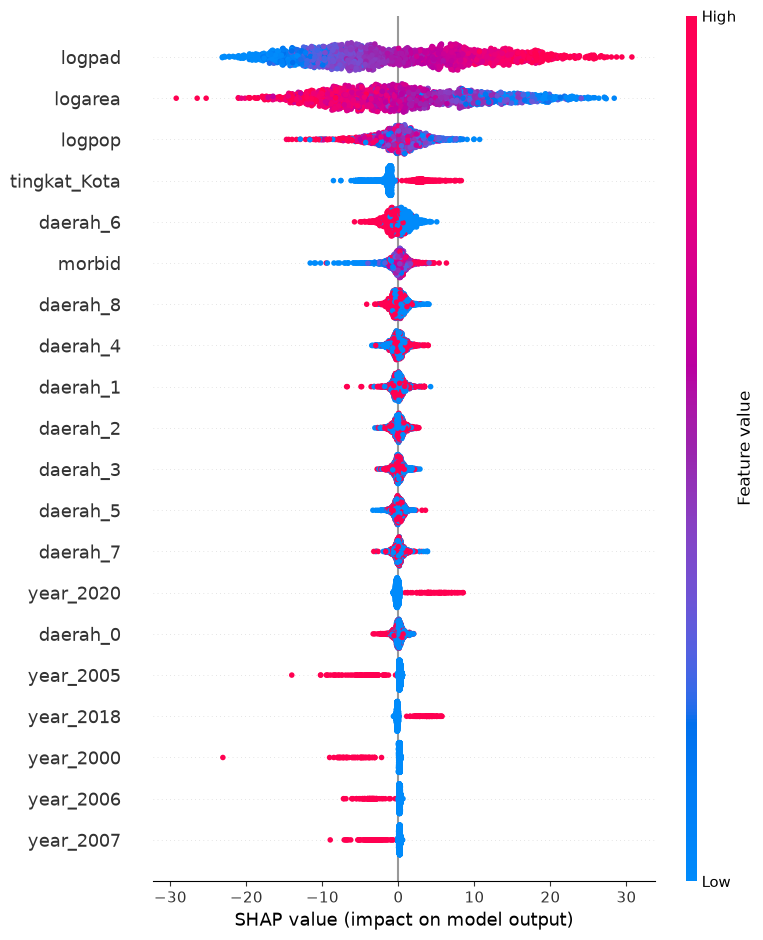

In [50]:
shap.summary_plot(shap_values, X_test_final)

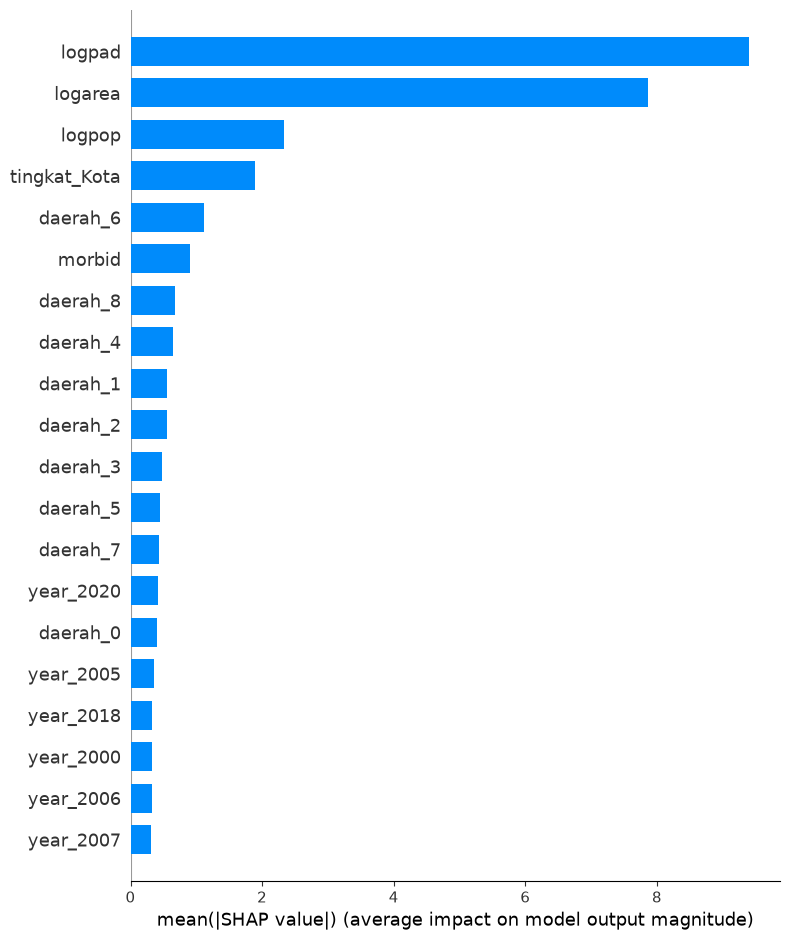

In [51]:
shap.summary_plot(shap_values, X_test_final, plot_type="bar")

# Forecast